<a href="https://colab.research.google.com/github/Tonelli2003/rastreio_profundidade/blob/main/CP_RastreioProfundidade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎯 Rastreio e Estimativa de Profundidade em Vídeo

**Disciplina:** Visão Computacional / Deep Learning  
| Nome | RM |
|------|----|
| Augusto Oliveira Codo de Sousa | RM562080 |
| Felipe de Oliveira Cabral | RM561720 |
| Gabriel Tonelli Avelino Dos Santos | RM564705 |
| Marcelo Roberto Maso Junior | RM562163 |
| Vinícius Adrian Siqueira de Oliveira | RM564962 |
| Sofia Bueris Netto de Souza | RM565818 |

> **Como usar:** `Ambiente de execução → Alterar tipo de ambiente de execução → GPU (T4)` e depois `Ambiente de execução → Executar tudo`.
> Os parâmetros ficam na seção 2 (formulários do Colab, com `#@param`). O sumário do relatório está no painel lateral esquerdo do Colab.

## 1. Objetivo e arquitetura

**Objetivo:** a partir de um vídeo (ou sequência de imagens de webcam), (i) localizar e segmentar os objetos, (ii) estimar a profundidade de cada objeto, (iii) descobrir qual está **mais próximo da câmera** e (iv) **rastreá-lo** ao longo do tempo, mantendo a identidade mesmo quando sai e volta ao quadro.

```
 frame ──► [Mask R-CNN]  ──► máscaras + caixas + classes
   │                                   │
   └──► [MiDaS-small (CNN)] ─► mapa de profundidade relativa
                                       │   mediana do mapa dentro de cada máscara
                                       ▼
                     proximidade de cada objeto (0 = longe, 1 = perto)
                                       │
                                       ▼
        [Tracker: Kalman + Húngaro (IoU + cor HSV) + re-identificação]
                                       │
                                       ▼
        [Seletor de alvo: objeto mais próximo, com histerese e paciência]
```

| Etapa | Modelo / técnica | Justificativa |
|---|---|---|
| Segmentação de instâncias | **Mask R-CNN** (ResNet-50 FPN v2, torchvision, pesos COCO) | Família R-CNN; devolve máscara por objeto, o que dá uma profundidade mais limpa que a caixa inteira |
| Profundidade | **MiDaS small** (CNN, Intel ISL) | Estima profundidade relativa (inversa) monocular; leve o bastante para o Colab |
| Rastreio | **Filtro de Kalman** (velocidade constante) + **algoritmo húngaro** (custo = IoU + histograma de cor) | Abordagem tipo SORT, com aparência para reduzir troca de IDs |
| Entrar/sair do quadro | **Galeria de tracks perdidos + re-identificação por cor** | Quando o objeto volta, recupera o mesmo ID em vez de criar um novo |

**Nota sobre profundidade:** o MiDaS devolve profundidade **relativa** (sem escala em metros). Basta para ordenar "quem está mais perto". Normalizamos por frame (percentis 2–98) e usamos a **mediana dentro da máscara** de cada objeto.

> **Sobre o "RNN" do enunciado:** para a segmentação usamos **Mask R-CNN** (rede convolucional baseada em regiões), a família R-CNN de segmentação de instâncias. Uma rede *recorrente* não é o modelo usual para segmentar objetos em uma imagem; interpretamos o termo do enunciado como R-CNN. A parte temporal (continuidade entre frames) é resolvida pelo tracker (Kalman + húngaro), não por uma rede recorrente.


## 2. Configuração do ambiente e parâmetros

In [ ]:
#@title 📦 Instalação e imports
!pip -q install timm

import os, glob, time, subprocess, urllib.request, warnings
from base64 import b64encode

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)
if device == "cpu":
    print("⚠️ Sem GPU: vai funcionar, mas devagar. Ative em Ambiente de execução → Alterar tipo → GPU.")

Dispositivo: cuda


In [ ]:
#@title ⚙️ Parâmetros (edite pelo formulário)
FONTE = "exemplo"  #@param ["exemplo", "upload", "pasta_de_imagens"]
VIDEO_EXEMPLO = "store-aisle-detection.mp4"  #@param ["store-aisle-detection.mp4", "one-by-one-person-detection.mp4", "person-bicycle-car-detection.mp4"]
# Vídeos de exemplo (Intel). Só vale quando FONTE = "exemplo". Prefira um com vários objetos ao mesmo tempo.
CAMINHO_PASTA = "/content/frames"  #@param {type:"string"}
MAX_FRAMES = 360  #@param {type:"integer"}
FRAME_INICIAL = -1  #@param {type:"integer"}
PASSO_FRAMES = 0  #@param {type:"integer"}
# FRAME_INICIAL = -1 e PASSO_FRAMES = 0 usam o preset do vídeo de exemplo (o corredor só tem gente a partir do frame ~540).
# PASSO_FRAMES = N usa 1 frame a cada N (vídeos de 60 FPS rendem bem com passo 5).
LARGURA = 640  #@param {type:"integer"}

# --- Detecção
SCORE_MIN = 0.5  #@param {type:"slider", min:0.3, max:0.95, step:0.05}
CLASSES_INTERESSE = "person, car, bicycle, motorcycle, bus, truck, dog, cat"  #@param {type:"string"}
# Nomes de classes COCO separados por vírgula. Deixe vazio para aceitar todas as classes.
CLASSES_SET = {c.strip() for c in CLASSES_INTERESSE.split(",") if c.strip()}

# --- Tracking
MAX_AGE = 15  #@param {type:"integer"}
MIN_HITS = 3  #@param {type:"integer"}
GATE = 0.75  #@param {type:"number"}
MAX_LOST = 120  #@param {type:"integer"}
REID_THR = 0.45  #@param {type:"number"}

# --- Seleção do alvo (objeto mais próximo)
MARGEM_TROCA = 0.15  #@param {type:"number"}
PACIENCIA = 60  #@param {type:"integer"}

# --- Avaliação
GAP_TESTE = 30  #@param {type:"integer"}
# Duração (frames) da ausência forçada no teste de saída do quadro (precisa ser > MAX_AGE).


In [ ]:
#@title 🎞️ Entrada de dados (vídeo de exemplo, upload ou pasta de imagens da webcam)
URL_EXEMPLO = "https://github.com/intel-iot-devkit/sample-videos/raw/master/" + VIDEO_EXEMPLO

if FONTE == "exemplo":
    CAMINHO = VIDEO_EXEMPLO
    if not os.path.exists(CAMINHO):
        urllib.request.urlretrieve(URL_EXEMPLO, CAMINHO)
elif FONTE == "upload":
    from google.colab import files
    up = files.upload()
    CAMINHO = list(up.keys())[0]
else:
    CAMINHO = CAMINHO_PASTA

# Presets (frame inicial, passo) por vídeo de exemplo; o corredor está vazio até ~6 s e roda a 60 FPS.
PRESETS = {"store-aisle-detection.mp4": (540, 5), "one-by-one-person-detection.mp4": (330, 2),
           "person-bicycle-car-detection.mp4": (0, 1)}
_ini, _passo = PRESETS.get(VIDEO_EXEMPLO, (0, 1)) if FONTE == "exemplo" else (0, 1)
INICIO = _ini if FRAME_INICIAL < 0 else FRAME_INICIAL
PASSO = _passo if PASSO_FRAMES <= 0 else PASSO_FRAMES

if FONTE == "pasta_de_imagens":
    FPS_VIDEO = 10.0 / PASSO
else:
    _cap = cv2.VideoCapture(CAMINHO)
    FPS_VIDEO = (_cap.get(cv2.CAP_PROP_FPS) or 25.0) / PASSO  # FPS efetivo depois do passo
    _cap.release()


def iter_frames(fonte, caminho, max_frames, largura):
    # Gera frames BGR redimensionados (largura fixa, altura par para o codec H.264).
    def redimensiona(f):
        h, w = f.shape[:2]
        return cv2.resize(f, (largura, int(round(h * largura / w / 2) * 2)))

    if fonte == "pasta_de_imagens":
        arqs = sorted(sum([glob.glob(os.path.join(caminho, e)) for e in ("*.jpg", "*.jpeg", "*.png")], []))
        for a in arqs[INICIO::PASSO][:max_frames]:
            yield redimensiona(cv2.imread(a))
    else:
        cap = cv2.VideoCapture(caminho)
        cap.set(cv2.CAP_PROP_POS_FRAMES, INICIO)
        n = 0
        while n < max_frames:
            ok, f = cap.read()
            if not ok:
                break
            yield redimensiona(f)
            n += 1
            for _ in range(PASSO - 1):  # pula frames para respeitar o passo
                cap.grab()
        cap.release()


print(f"Fonte: {FONTE} | arquivo/pasta: {CAMINHO} | início: frame {INICIO} | passo: {PASSO} | FPS efetivo: {FPS_VIDEO:.1f}")

Fonte: exemplo | arquivo/pasta: store-aisle-detection.mp4 | início: frame 540 | passo: 5 | FPS efetivo: 12.0


## 3. Modelos pré-treinados

* **Mask R-CNN** segmenta cada instância (máscara + caixa + classe COCO).
* **MiDaS small** é uma CNN que prevê profundidade relativa inversa: **valores maiores = mais perto**.

In [ ]:
#@title 🧠 Carregar Mask R-CNN e MiDaS
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights

pesos = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
seg_model = maskrcnn_resnet50_fpn_v2(weights=pesos).to(device).eval()
CATEGORIAS = pesos.meta["categories"]

midas = torch.hub.load("intel-isl/MiDaS", "MiDaS_small", trust_repo=True).to(device).eval()
midas_tf = torch.hub.load("intel-isl/MiDaS", "transforms", trust_repo=True).small_transform
print("Modelos carregados.")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:02<00:00, 89.0MB/s]


Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip
Loading weights:  None
The repository rwightman_gen-efficientnet-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/rwightman/gen-efficientnet-pytorch/zipball/master" to /root/.cache/torch/hub/master.zip
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights/tf_efficientnet_lite3-b733e338.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientnet_lite3-b733e338.pth
Downloading: "https://github.com/isl-org/MiDaS/releases/download/v2_1/midas_v21_small_256.pt" to /root/.cache/torch/hub/checkpoints/midas_v21_small_256.pt


100%|██████████| 81.8M/81.8M [00:00<00:00, 244MB/s]


Modelos carregados.


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


In [ ]:
#@title 🔧 Funções: segmentação, profundidade, aparência
def sync():
    if device == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def segmentar(frame_rgb):
    # Mask R-CNN: devolve caixas (xyxy), rótulos, scores e máscaras booleanas.
    t = torch.from_numpy(frame_rgb).permute(2, 0, 1).float().div(255).to(device)
    out = seg_model([t])[0]
    keep = out["scores"] >= SCORE_MIN
    return dict(
        boxes=out["boxes"][keep].cpu().numpy(),
        labels=out["labels"][keep].cpu().numpy(),
        scores=out["scores"][keep].cpu().numpy(),
        masks=(out["masks"][keep, 0] > 0.5).cpu().numpy(),
    )


@torch.no_grad()
def profundidade(frame_rgb):
    # MiDaS: mapa de proximidade relativa em [0, 1] (1 = mais perto), normalizado por percentis.
    p = midas(midas_tf(frame_rgb).to(device))
    p = F.interpolate(p.unsqueeze(1), size=frame_rgb.shape[:2], mode="bicubic", align_corners=False)
    p = p.squeeze().cpu().numpy()
    lo, hi = np.percentile(p, [2, 98])
    return np.clip((p - lo) / (hi - lo + 1e-6), 0, 1)


def hist_hsv(frame_bgr, mask):
    # Histograma HSV (H x S) dos pixels da máscara: descritor de aparência para o tracker.
    hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1], mask.astype(np.uint8) * 255, [16, 8], [0, 180, 0, 256])
    cv2.normalize(h, h, 1, 0, cv2.NORM_L1)
    return h.flatten().astype(np.float32)


def hist_dist(a, b):
    return float(cv2.compareHist(a, b, cv2.HISTCMP_BHATTACHARYYA))  # 0 = igual, 1 = diferente


def construir_deteccoes(frame_bgr, seg, depth):
    # Junta segmentação + profundidade: cada detecção recebe sua 'proximidade' (mediana na máscara).
    dets = []
    for box, lab, sc, m in zip(seg["boxes"], seg["labels"], seg["scores"], seg["masks"]):
        if m.sum() < 50:
            continue
        if CLASSES_SET and CATEGORIAS[lab] not in CLASSES_SET:
            continue  # ignora classes fora do interesse (reduz falsos positivos)
        dets.append(dict(box=box.astype(float), cls=CATEGORIAS[lab], score=float(sc),
                         closeness=float(np.median(depth[m])), hist=hist_hsv(frame_bgr, m), mask=m))
    return dets

## 4. Rastreio de objetos

Cada objeto é um **track** com um **filtro de Kalman** de velocidade constante (estado: centro, largura, altura e suas velocidades). A cada frame:

1. **Predição** da posição de todos os tracks.
2. **Associação** detecção ↔ track pelo **algoritmo húngaro**, com custo `0,6·(1−IoU) + 0,4·distância_de_cor` e *gating* (mesma classe, IoU mínimo, custo máximo).
3. **Atualização** dos tracks casados; tracks sem detecção continuam sendo previstos por até `MAX_AGE` frames (oclusão curta).
4. Passou de `MAX_AGE`: o track vai para uma **galeria de perdidos** (guarda ID e aparência por `MAX_LOST` frames).
5. Detecção nova sem par: tenta **re-identificação** comparando a cor com a galeria. Se parecer com um perdido da mesma classe (`distância < REID_THR`), **o ID antigo é reativado**; senão nasce um ID novo.

Um **seletor de alvo** escolhe o objeto mais próximo, com **histerese** (só troca se outro estiver `MARGEM_TROCA` mais perto) e **paciência** (espera `PACIENCIA` frames pelo alvo que saiu antes de escolher outro).

In [ ]:
#@title 🧮 Tracker: Kalman + Húngaro + re-identificação
def iou_matrix(a, b):
    a = np.asarray(a, float).reshape(-1, 4)
    b = np.asarray(b, float).reshape(-1, 4)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


class KalmanBox:
    # Filtro de Kalman de velocidade constante. Estado: [cx, cy, w, h, vx, vy, vw, vh].
    def __init__(self, box):
        x1, y1, x2, y2 = box
        self.x = np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1, 0, 0, 0, 0], float)
        self.P = np.diag([10, 10, 10, 10, 1e3, 1e3, 1e3, 1e3]).astype(float)
        self.F = np.eye(8); self.F[:4, 4:] = np.eye(4)
        self.H = np.eye(4, 8)
        self.Q = np.diag([1, 1, 1, 1, .1, .1, .1, .1])
        self.R = np.diag([4, 4, 8, 8])

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, box):
        x1, y1, x2, y2 = box
        z = np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], float)
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ (z - self.H @ self.x)
        self.P = (np.eye(8) - K @ self.H) @ self.P

    @property
    def box(self):
        cx, cy, w, h = self.x[:4]
        w, h = max(w, 1.0), max(h, 1.0)
        return np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])


class Track:
    def __init__(self, det, track_id, frame_idx):
        self.id = track_id
        self.cls = det["cls"]
        self.kf = KalmanBox(det["box"])
        self.hist = det["hist"].copy()
        self.closeness = det["closeness"]
        self.det = det
        self.hits, self.age, self.tsu = 1, 0, 0  # acertos, idade, frames desde a última atualização
        self.lost_since = None
        self.trail = [tuple(self.kf.x[:2])]

    @property
    def box(self):
        return self.kf.box

    def predict(self):
        self.kf.predict()
        self.age += 1
        self.tsu += 1

    def update(self, det):
        self.kf.update(det["box"])
        self.det = det
        self.hits += 1
        self.tsu = 0
        self.hist = 0.8 * self.hist + 0.2 * det["hist"]          # aparência com média móvel
        self.closeness = 0.6 * self.closeness + 0.4 * det["closeness"]  # profundidade suavizada
        self.trail.append(tuple(self.kf.x[:2]))


class Tracker:
    def __init__(self, reid=True):
        self.reid = reid
        self.tracks, self.lost = [], []
        self.next_id, self.n_reid = 1, 0

    def _associar(self, dets):
        if not self.tracks or not dets:
            return [], list(range(len(self.tracks))), list(range(len(dets)))
        iou = iou_matrix([t.box for t in self.tracks], [d["box"] for d in dets])
        hd = np.array([[hist_dist(t.hist, d["hist"]) for d in dets] for t in self.tracks])
        custo = 0.6 * (1 - iou) + 0.4 * hd
        custo[iou < 0.1] = 1e3
        for i, t in enumerate(self.tracks):
            for j, d in enumerate(dets):
                if t.cls != d["cls"]:
                    custo[i, j] = 1e3
        r, c = linear_sum_assignment(custo)
        matches = [(i, j) for i, j in zip(r, c) if custo[i, j] < GATE]
        mt, md_ = {i for i, _ in matches}, {j for _, j in matches}
        return (matches, [i for i in range(len(self.tracks)) if i not in mt],
                [j for j in range(len(dets)) if j not in md_])

    def _reidentificar(self, det):
        cands = [(hist_dist(t.hist, det["hist"]), t) for t in self.lost if t.cls == det["cls"]]
        if not cands:
            return None
        dist, t = min(cands, key=lambda x: x[0])
        if dist >= REID_THR:
            return None
        self.lost.remove(t)
        t.kf = KalmanBox(det["box"])  # reinicia o filtro na nova posição
        t.update(det)
        t.tsu = 0
        return t

    def update(self, dets, frame_idx):
        # Processa um frame e devolve os tracks visíveis (confirmados e atualizados neste frame).
        for t in self.tracks:
            t.predict()
        matches, _, un_d = self._associar(dets)
        for ti, di in matches:
            self.tracks[ti].update(dets[di])
        for di in un_d:
            tr = self._reidentificar(dets[di]) if self.reid else None
            if tr is None:
                tr = Track(dets[di], self.next_id, frame_idx)
                self.next_id += 1
            else:
                self.n_reid += 1
            self.tracks.append(tr)

        vivos = []
        for t in self.tracks:
            if t.hits < MIN_HITS and t.tsu > 3:       # candidato espúrio: descarta rápido
                continue
            if t.tsu > MAX_AGE:                        # saiu de cena: vai para a galeria
                if t.hits >= MIN_HITS and self.reid:
                    t.lost_since = frame_idx
                    self.lost.append(t)
                continue
            vivos.append(t)
        self.tracks = vivos
        self.lost = [t for t in self.lost if frame_idx - t.lost_since <= MAX_LOST]
        return [t for t in self.tracks if t.tsu == 0 and (t.hits >= MIN_HITS or frame_idx < MIN_HITS)]


class AlvoManager:
    # Mantém o ID do alvo = objeto mais próximo, com histerese e paciência.
    def __init__(self):
        self.id, self.ausente = None, 0

    def step(self, visiveis):
        por_id = {t.id: t for t in visiveis}
        if self.id in por_id:
            self.ausente = 0
            melhor = max(visiveis, key=lambda t: t.closeness)
            if melhor.id != self.id and melhor.closeness > por_id[self.id].closeness + MARGEM_TROCA:
                self.id = melhor.id
        else:
            if self.id is not None:
                self.ausente += 1
            if (self.id is None or self.ausente > PACIENCIA) and visiveis:
                self.id = max(visiveis, key=lambda t: t.closeness).id
                self.ausente = 0
        return self.id

## 5. Execução do pipeline completo

Para cada frame: segmentação → profundidade → proximidade por objeto → tracking → escolha do alvo → desenho. O vídeo anotado é salvo e todas as medições são registradas para o relatório de evidências (seção 6).

In [ ]:
#@title 🎨 Funções de desenho
def cor_id(i):
    hue = int((i * 47) % 180)
    c = cv2.cvtColor(np.uint8([[[hue, 220, 255]]]), cv2.COLOR_HSV2BGR)[0, 0]
    return tuple(int(x) for x in c)


def depth_colorido(depth):
    return cv2.applyColorMap((depth * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)  # claro = perto


def desenhar(frame, visiveis, alvo_id, depth, i, fps):
    over = frame.copy()
    for t in visiveis:
        over[t.det["mask"]] = cor_id(t.id)
    vis = cv2.addWeighted(over, 0.4, frame, 0.6, 0)
    for t in visiveis:
        x1, y1, x2, y2 = map(int, t.det["box"])
        eh_alvo = t.id == alvo_id
        cor = (0, 0, 255) if eh_alvo else cor_id(t.id)
        cv2.rectangle(vis, (x1, y1), (x2, y2), cor, 4 if eh_alvo else 2)
        rot = f"#{t.id} {t.cls} {t.closeness:.2f}" + (" << ALVO" if eh_alvo else "")
        cv2.putText(vis, rot, (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3)
        cv2.putText(vis, rot, (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, cor, 1)
        pts = np.array(t.trail[-30:], np.int32).reshape(-1, 1, 2)
        if len(pts) > 1:
            cv2.polylines(vis, [pts], False, cor, 2)
    # inset com o mapa de profundidade
    h, w = vis.shape[:2]
    inset = cv2.resize(depth_colorido(depth), (w // 4, h // 4))
    vis[8:8 + inset.shape[0], w - 8 - inset.shape[1]:w - 8] = inset
    cv2.rectangle(vis, (w - 8 - inset.shape[1], 8), (w - 8, 8 + inset.shape[0]), (255, 255, 255), 1)
    txt = f"frame {i} | {fps:.1f} FPS | alvo: {'#' + str(alvo_id) if alvo_id else '-'}"
    cv2.putText(vis, txt, (8, h - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 3)
    cv2.putText(vis, txt, (8, h - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
    return vis

In [ ]:
#@title ▶️ Rodar o sistema
SAIDA_RAW, SAIDA_MP4 = "saida_raw.mp4", "saida_rastreio.mp4"
tracker, alvo_mgr = Tracker(reid=True), AlvoManager()
cache, registros, alvo_por_frame = [], [], []
tempos = {"segmentacao": [], "profundidade": [], "tracking": [], "total": []}
chaves = set(range(0, MAX_FRAMES, max(1, MAX_FRAMES // 8)))
amostras = {}
vw = None

for i, frame in enumerate(iter_frames(FONTE, CAMINHO, MAX_FRAMES, LARGURA)):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    t0 = time.time()
    seg = segmentar(rgb); sync(); t1 = time.time()
    depth = profundidade(rgb); sync(); t2 = time.time()
    dets = construir_deteccoes(frame, seg, depth)
    visiveis = tracker.update(dets, i)
    alvo_id = alvo_mgr.step(visiveis); t3 = time.time()

    tempos["segmentacao"].append(t1 - t0); tempos["profundidade"].append(t2 - t1)
    tempos["tracking"].append(t3 - t2); tempos["total"].append(t3 - t0)
    cache.append([{k: v for k, v in d.items() if k != "mask"} for d in dets])  # p/ ablação
    alvo_por_frame.append(alvo_id)
    for t in visiveis:
        x1, y1, x2, y2 = t.det["box"]
        registros.append(dict(frame=i, id=t.id, cls=t.cls, closeness=t.det["closeness"],
                              x1=x1, y1=y1, x2=x2, y2=y2, alvo=(t.id == alvo_id)))

    anot = desenhar(frame, visiveis, alvo_id, depth, i, 1 / max(t3 - t0, 1e-6))
    if vw is None:
        vw = cv2.VideoWriter(SAIDA_RAW, cv2.VideoWriter_fourcc(*"mp4v"), FPS_VIDEO,
                             (anot.shape[1], anot.shape[0]))
    vw.write(anot)
    if i in chaves:
        amostras[i] = (rgb, cv2.cvtColor(depth_colorido(depth), cv2.COLOR_BGR2RGB),
                       cv2.cvtColor(anot, cv2.COLOR_BGR2RGB))
    if i % 40 == 0:
        print(f"frame {i:4d} | objetos: {len(dets)} | visíveis: {len(visiveis)} | alvo: {alvo_id}")

vw.release()
N_FRAMES = len(cache)
df = pd.DataFrame(registros, columns=["frame", "id", "cls", "closeness", "x1", "y1", "x2", "y2", "alvo"])
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", SAIDA_RAW, "-vcodec", "libx264",
                "-pix_fmt", "yuv420p", SAIDA_MP4], check=True)
if df.empty:
    raise RuntimeError(
        "Nenhum objeto foi rastreado em nenhum frame. Verifique: (1) o trecho lido tem objetos? ajuste FRAME_INICIAL/PASSO_FRAMES "
        "(o vídeo salvo em saida_rastreio.mp4 mostra o que foi lido); (2) CLASSES_INTERESSE inclui as classes certas; "
        "(3) SCORE_MIN muito alto; tente 0.4.")
print(f"\nConcluído: {N_FRAMES} frames, {df['id'].nunique()} IDs, {tracker.n_reid} re-identificações.")

frame    0 | objetos: 1 | visíveis: 1 | alvo: 1
frame   40 | objetos: 2 | visíveis: 2 | alvo: 2
frame   80 | objetos: 3 | visíveis: 2 | alvo: 2
frame  120 | objetos: 3 | visíveis: 3 | alvo: 3
frame  160 | objetos: 3 | visíveis: 3 | alvo: 3
frame  200 | objetos: 3 | visíveis: 3 | alvo: 3
frame  240 | objetos: 5 | visíveis: 5 | alvo: 8
frame  280 | objetos: 5 | visíveis: 5 | alvo: 8
frame  320 | objetos: 5 | visíveis: 5 | alvo: 8

Concluído: 360 frames, 8 IDs, 1 re-identificações.


,frames,frames_com_objeto,frames_com_2_ou_mais,max_simultaneos,ids_unicos
0,360,360,331,6,8


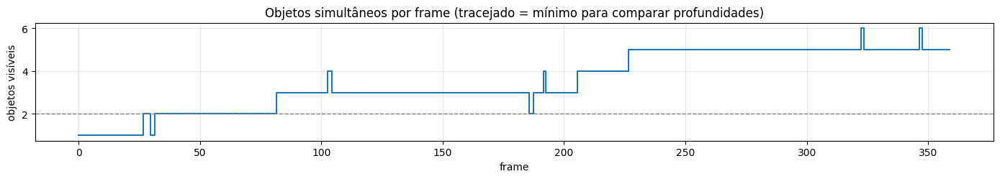

✅ 331 frames com 2+ objetos: a escolha do 'mais próximo' é realmente testada.


In [ ]:
#@title 🔎 Diagnóstico de cobertura do experimento
# Antes de interpretar qualquer métrica, verifica se o vídeo realmente exercita o sistema:
# o critério "objeto mais próximo" só faz sentido em frames com 2 ou mais objetos visíveis.
n_por_frame = df.groupby("frame")["id"].nunique().reindex(range(N_FRAMES), fill_value=0)
n_multi = int((n_por_frame >= 2).sum())
cobertura = dict(frames=N_FRAMES,
                 frames_com_objeto=int((n_por_frame >= 1).sum()),
                 frames_com_2_ou_mais=n_multi,
                 max_simultaneos=int(n_por_frame.max()),
                 ids_unicos=int(df["id"].nunique()))
display(pd.DataFrame([cobertura]))

plt.figure(figsize=(14, 2.6))
plt.step(n_por_frame.index, n_por_frame.values, where="mid")
plt.axhline(2, ls="--", c="gray", lw=1)
plt.xlabel("frame"); plt.ylabel("objetos visíveis"); plt.grid(alpha=.3)
plt.title("Objetos simultâneos por frame (tracejado = mínimo para comparar profundidades)")
plt.tight_layout(); plt.show()

LIMIAR_MULTI = 20
if n_multi >= LIMIAR_MULTI:
    print(f"✅ {n_multi} frames com 2+ objetos: a escolha do 'mais próximo' é realmente testada.")
else:
    print(f"⚠️ Só {n_multi} frames com 2+ objetos (mínimo recomendado: {LIMIAR_MULTI}). "
          "As métricas de profundidade e de alvo ficam pouco conclusivas: troque VIDEO_EXEMPLO "
          "ou use um vídeo seu com vários objetos a distâncias diferentes e rode novamente.")

## 6. Relatório de evidências

### 6.1 Vídeo com o resultado
Cores = IDs; contorno **vermelho** = alvo (objeto mais próximo); linha = trajetória; canto superior direito = mapa de profundidade (claro = perto).

In [ ]:
#@title 🎬 Vídeo anotado
dados = b64encode(open(SAIDA_MP4, "rb").read()).decode()
display(HTML(f'<video width="720" controls><source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))

### 6.2 Quadros-chave: original × profundidade × segmentação + tracking

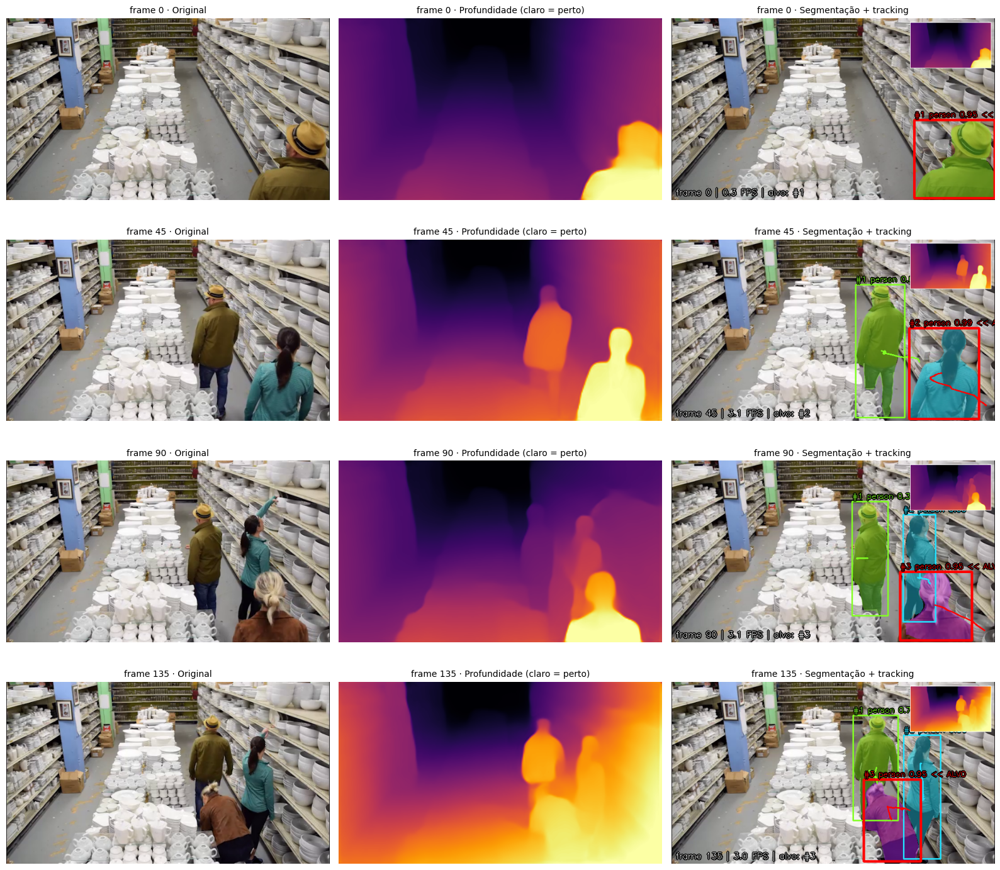

In [ ]:
#@title 🖼️ Montagem de quadros-chave
ks = [k for k in sorted(amostras) if k in set(df["frame"])][:4] or sorted(amostras)[:4]
fig, axs = plt.subplots(len(ks), 3, figsize=(16, 3.6 * len(ks)))
axs = np.atleast_2d(axs)
for r, k in enumerate(ks):
    for c, (img, tit) in enumerate(zip(amostras[k], ["Original", "Profundidade (claro = perto)", "Segmentação + tracking"])):
        axs[r, c].imshow(img); axs[r, c].axis("off")
        axs[r, c].set_title(f"frame {k} · {tit}", fontsize=10)
plt.tight_layout(); plt.show()

### 6.3 Profundidade estimada por objeto ao longo do tempo
Cada linha é um ID. Os pontos pretos marcam os frames em que aquele ID era o **alvo**. A linha inferior mostra qual ID foi o alvo em cada frame.

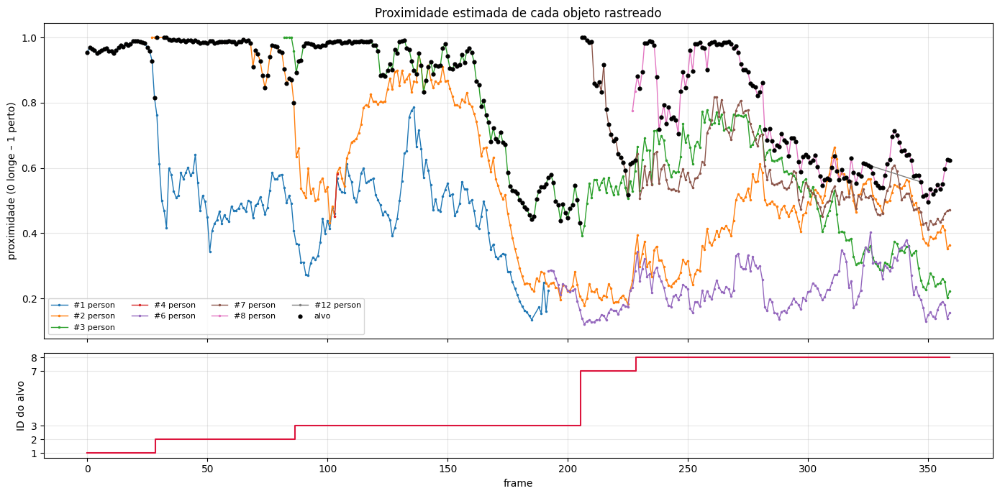

In [ ]:
#@title 📈 Proximidade por ID e alvo ao longo do tempo
fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for oid, g in df.groupby("id"):
    a1.plot(g["frame"], g["closeness"], ".-", ms=3, lw=1, label=f"#{oid} {g['cls'].iloc[0]}")
alvo_df = df[df["alvo"]]
a1.scatter(alvo_df["frame"], alvo_df["closeness"], c="k", s=12, zorder=3, label="alvo")
a1.set_ylabel("proximidade (0 longe – 1 perto)"); a1.legend(ncol=4, fontsize=8); a1.grid(alpha=.3)
a1.set_title("Proximidade estimada de cada objeto rastreado")
x = np.arange(N_FRAMES); y = np.array([a if a else np.nan for a in alvo_por_frame], float)
a2.step(x, y, where="mid", c="crimson"); a2.set_ylabel("ID do alvo"); a2.set_xlabel("frame"); a2.grid(alpha=.3)
a2.set_yticks(sorted(set(int(v) for v in y if not np.isnan(v))))
plt.tight_layout(); plt.show()

### 6.4 Linha do tempo dos tracks (entradas e saídas do quadro)
Lacunas dentro da mesma barra = objeto saiu do quadro (ou foi ocluído) e **voltou com o mesmo ID**.

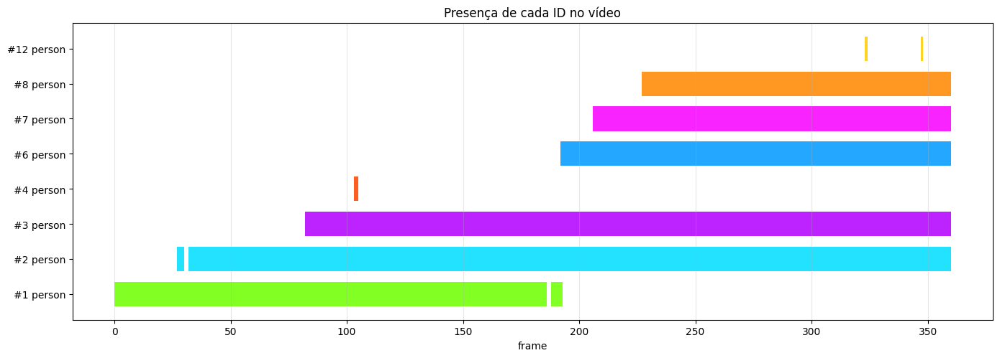

In [ ]:
#@title 🕒 Linha do tempo de presença por ID
def corridas(frames):
    frames = sorted(frames); ini = prev = frames[0]; out = []
    for f in frames[1:]:
        if f != prev + 1:
            out.append((ini, prev - ini + 1)); ini = f
        prev = f
    out.append((ini, prev - ini + 1)); return out

ids = sorted(df["id"].unique())
fig, ax = plt.subplots(figsize=(14, 0.45 * len(ids) + 1.5))
for row, oid in enumerate(ids):
    ax.broken_barh(corridas(df[df["id"] == oid]["frame"]), (row - .35, .7),
                   facecolors=[c / 255 for c in cor_id(oid)[::-1]])
ax.set_yticks(range(len(ids))); ax.set_yticklabels([f"#{i} {df[df['id']==i]['cls'].iloc[0]}" for i in ids])
ax.set_xlabel("frame"); ax.set_title("Presença de cada ID no vídeo"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

,id,classe,ultimo_frame_visto,frame_de_volta,frames_ausente
0,12,person,323,347,23


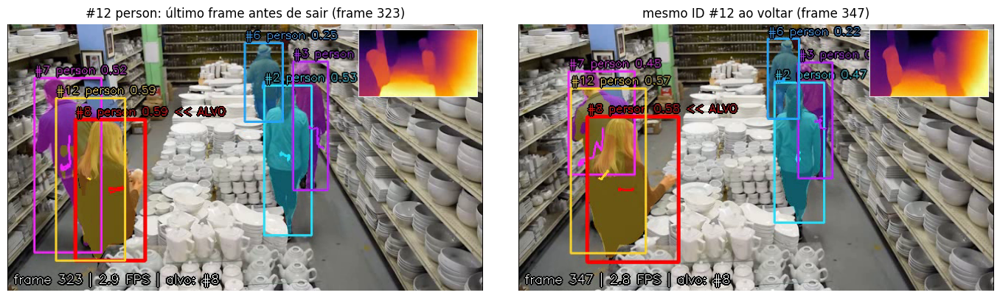

In [ ]:
#@title 🔁 Eventos de saída e re-entrada com o mesmo ID
LACUNA_MIN = 5
eventos = []
for oid, g in df.groupby("id"):
    f = np.sort(g["frame"].unique())
    for a, b in zip(f[:-1], f[1:]):
        if b - a - 1 >= LACUNA_MIN:
            eventos.append(dict(id=oid, classe=g["cls"].iloc[0], ultimo_frame_visto=int(a),
                                frame_de_volta=int(b), frames_ausente=int(b - a - 1)))
ev = pd.DataFrame(eventos)
if ev.empty:
    print("Nenhuma re-entrada com ≥", LACUNA_MIN, "frames neste vídeo (retorno natural). A evidência de re-ID vem do teste de saída forçada (6.5b); "
          "para um retorno natural, grave um vídeo em que um objeto saia e volte ao quadro.")
else:
    display(ev)

    def ler_frame(caminho, idx):
        cap = cv2.VideoCapture(caminho); cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, f = cap.read(); cap.release()
        return cv2.cvtColor(f, cv2.COLOR_BGR2RGB)

    for _, e in ev.head(3).iterrows():
        fig, axs = plt.subplots(1, 2, figsize=(14, 4))
        axs[0].imshow(ler_frame(SAIDA_RAW, e["ultimo_frame_visto"])); axs[0].axis("off")
        axs[0].set_title(f"#{e['id']} {e['classe']}: último frame antes de sair (frame {e['ultimo_frame_visto']})")
        axs[1].imshow(ler_frame(SAIDA_RAW, e["frame_de_volta"])); axs[1].axis("off")
        axs[1].set_title(f"mesmo ID #{e['id']} ao voltar (frame {e['frame_de_volta']})")
        plt.tight_layout(); plt.show()

In [ ]:
#@title 🧾 Relatório cronológico de entradas e saídas do quadro
# Uma "saída" é uma ausência de pelo menos LACUNA_MIN frames; menos que isso é tratado como oclusão.
def segmentos(frames, lacuna):
    frames = sorted(set(int(f) for f in frames))
    segs, ini, prev = [], frames[0], frames[0]
    for f in frames[1:]:
        if f - prev - 1 >= lacuna:
            segs.append((ini, prev)); ini = f
        prev = f
    segs.append((ini, prev)); return segs

log = []
for oid, g in df.groupby("id"):
    segs = segmentos(g["frame"], LACUNA_MIN)
    classe = g["cls"].iloc[0]
    for k, (a, b) in enumerate(segs):
        log.append(dict(frame=a, id=oid, classe=classe, evento="ENTROU" if k == 0 else "VOLTOU (mesmo ID)"))
        if k < len(segs) - 1 or b < N_FRAMES - 1:
            log.append(dict(frame=b, id=oid, classe=classe, evento="SAIU"))
rel = pd.DataFrame(log).sort_values(["frame", "id"]).reset_index(drop=True)
rel["tempo_s"] = (rel["frame"] / FPS_VIDEO).round(2)
display(rel[["tempo_s", "frame", "id", "classe", "evento"]])

# Alvo: quando começou e terminou cada período como objeto mais próximo
alvo_seg = []
atual, ini = None, 0
for k, a in enumerate(alvo_por_frame + [object()]):
    if a != atual:
        if atual is not None:
            alvo_seg.append(dict(alvo=f"#{atual}", frame_ini=ini, frame_fim=k - 1,
                                 duracao_s=round((k - ini) / FPS_VIDEO, 2)))
        atual, ini = a, k
display(pd.DataFrame(alvo_seg))

,tempo_s,frame,id,classe,evento
0,0.00,0,1,person,ENTROU
1,2.25,27,2,person,ENTROU
2,6.84,82,3,person,ENTROU
3,8.59,103,4,person,ENTROU
4,8.68,104,4,person,SAIU
5,16.02,192,1,person,SAIU
6,16.02,192,6,person,ENTROU
7,17.18,206,7,person,ENTROU
8,18.94,227,8,person,ENTROU
9,26.94,323,12,person,ENTROU


,alvo,frame_ini,frame_fim,duracao_s
0,#1,0,28,2.42
1,#2,29,86,4.84
2,#3,87,205,9.93
3,#7,206,228,1.92
4,#8,229,359,10.93


### 6.5 Ablação: a re-identificação realmente ajuda?
Reexecutamos **somente o tracker** nas mesmas detecções (cache), com e sem re-identificação. Sem ela, cada retorno de um objeto cria um ID novo (fragmentação). **Menos IDs únicos para o mesmo vídeo = identidades mais consistentes.**

Se o vídeo não tem retornos naturais, os dois resultados saem iguais. Por isso a seção 6.5b força uma saída do quadro para medir o efeito da re-identificação.


In [ ]:
#@title 🧪 Ablação do tracker (com × sem re-ID)
def rodar_cache(reid):
    tr = Tracker(reid=reid); vistos = {}
    for k, dets in enumerate(cache):
        for t in tr.update(dets, k):
            vistos.setdefault(t.id, []).append(k)
    vida = [len(v) for v in vistos.values()]
    return dict(config="com re-identificação" if reid else "sem re-identificação",
                ids_unicos=len(vistos), reidentificacoes=tr.n_reid,
                frames_medios_por_id=round(float(np.mean(vida)), 1) if vida else 0)

abl = pd.DataFrame([rodar_cache(True), rodar_cache(False)])
display(abl)
ok = abl.loc[0, "ids_unicos"] == df["id"].nunique()
print("Reprodutibilidade (cache == execução principal):", "OK" if ok else "diferença detectada")

,config,ids_unicos,reidentificacoes,frames_medios_por_id
0,com re-identificação,8,1,157.4
1,sem re-identificação,8,0,157.2


Reprodutibilidade (cache == execução principal): OK


### 6.5b Teste de saída forçada (oclusão artificial)
Pega o objeto com a maior presença contínua e **remove suas detecções por vários frames** (mais que `MAX_AGE`), como se ele tivesse saído do quadro. Em seguida roda só o tracker, com e sem re-identificação, e mede em quantos frames, depois da volta, o **mesmo objeto mantém o mesmo ID**. Isso gera evidência de re-ID mesmo quando o vídeo não tem retornos naturais.

Alvo do teste: ID #2 | ausente nos frames 181–210 (30 frames > MAX_AGE=15)


,config,id_antes,ids_apos,continuidade_pct,ids_unicos,reidentificacoes
0,com re-identificação,2,[2],100.0,8,2
1,sem re-identificação,2,[8],0.0,9,0


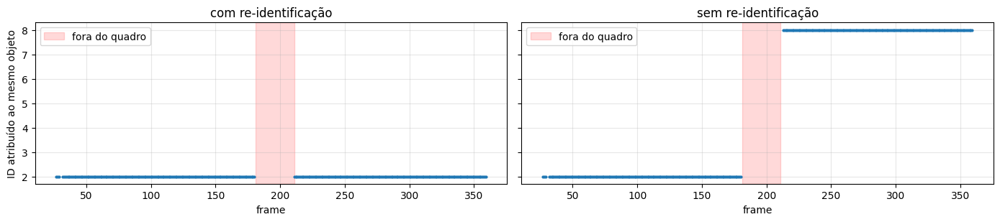

✅ Com re-ID o objeto manteve o mesmo ID em 100% dos frames após a volta; sem re-ID, 0%.


In [ ]:
#@title 🚪 Teste de saída forçada: o ID sobrevive a uma ausência longa?
def teste_saida_forcada(gap):
    # 1) escolhe o ID com a maior presença contínua no vídeo
    melhor = None
    for oid, g in df.groupby("id"):
        for ini, n in corridas(g["frame"]):
            if melhor is None or n > melhor[2]:
                melhor = (oid, ini, n)
    if melhor is None:
        return None, "nenhum track no vídeo"
    oid, ini, n = melhor
    antes_min, depois_min = MIN_HITS + 2, 5
    gap = min(gap, n - antes_min - depois_min)
    if gap <= MAX_AGE + 2:
        return None, (f"o maior track contínuo (ID #{oid}) tem só {n} frames; são necessários ao menos "
                      f"{MAX_AGE + 2 + antes_min + depois_min + 1} para forçar uma ausência maior que MAX_AGE={MAX_AGE}")
    a = ini + max(antes_min, (n - gap) // 2)
    b = a + gap                                   # frames [a, b): o alvo "sai do quadro"
    g = df[df["id"] == oid].set_index("frame")
    box_orig = {int(k): r[["x1", "y1", "x2", "y2"]].to_numpy(float) for k, r in g.iterrows()}

    # 2) remove as detecções do alvo durante a janela [a, b) (saída artificial do quadro)
    cache_mod = []
    for k, dets in enumerate(cache):
        if a <= k < b and k in box_orig:
            dets = [d for d in dets if iou_matrix([box_orig[k]], [d["box"]])[0, 0] < 0.3]
        cache_mod.append(dets)

    # 3) roda só o tracker e mede se o mesmo objeto mantém o mesmo ID depois da volta
    def rodar(reid):
        tr = Tracker(reid=reid)
        antes, depois, todos, serie = [], [], set(), []
        for k, dets in enumerate(cache_mod):
            vis = tr.update(dets, k)
            todos.update(t.id for t in vis)
            if k in box_orig and vis:
                ious = iou_matrix([box_orig[k]], [t.box for t in vis])[0]
                j = int(ious.argmax())
                if ious[j] > 0.5:
                    serie.append((k, vis[j].id))
                    if k < a:
                        antes.append(vis[j].id)
                    elif k >= b:
                        depois.append(vis[j].id)
        ref = max(set(antes), key=antes.count) if antes else None
        cont = float(np.mean([i == ref for i in depois])) if (depois and ref is not None) else float("nan")
        return serie, dict(config="com re-identificação" if reid else "sem re-identificação",
                           id_antes=ref, ids_apos=sorted(set(depois)),
                           continuidade_pct=round(100 * cont, 1) if cont == cont else float("nan"),
                           ids_unicos=len(todos), reidentificacoes=tr.n_reid)

    s_com, r_com = rodar(True)
    s_sem, r_sem = rodar(False)
    return dict(oid=int(oid), a=int(a), b=int(b), gap=int(b - a), series=(s_com, s_sem),
                tabela=pd.DataFrame([r_com, r_sem])), None


res_forcada, msg = teste_saida_forcada(GAP_TESTE)
if res_forcada is None:
    saida_forcada = None
    print("⚠️ Teste não executado:", msg)
else:
    saida_forcada = res_forcada
    tab_f = res_forcada["tabela"]
    print(f"Alvo do teste: ID #{res_forcada['oid']} | ausente nos frames {res_forcada['a']}–{res_forcada['b'] - 1} "
          f"({res_forcada['gap']} frames > MAX_AGE={MAX_AGE})")
    display(tab_f)

    fig, axs = plt.subplots(1, 2, figsize=(14, 3.2), sharey=True)
    for ax, serie, nome in zip(axs, res_forcada["series"], tab_f["config"]):
        if serie:
            ks, ids = zip(*serie)
            ax.plot(ks, ids, ".", ms=4)
        ax.axvspan(res_forcada["a"], res_forcada["b"], color="red", alpha=.15, label="fora do quadro")
        ax.set_title(nome); ax.set_xlabel("frame"); ax.grid(alpha=.3); ax.legend(loc="upper left")
    axs[0].set_ylabel("ID atribuído ao mesmo objeto")
    plt.tight_layout(); plt.show()

    c_com, c_sem = tab_f.loc[0, "continuidade_pct"], tab_f.loc[1, "continuidade_pct"]
    if c_com == c_com and c_com >= 90 and (c_sem != c_sem or c_sem < 50):
        print(f"✅ Com re-ID o objeto manteve o mesmo ID em {c_com:.0f}% dos frames após a volta; "
              f"sem re-ID, {('0' if c_sem != c_sem else format(c_sem, '.0f'))}%.")
    else:
        print(f"⚠️ Resultado não conclusivo a favor da re-ID (com: {c_com}%, sem: {c_sem}%). "
              "Experimente ajustar REID_THR ou use um vídeo em que o objeto tenha aparência distinta.")

### 6.6 Validação da profundidade estimada
Não há *ground truth* de profundidade neste vídeo, então usamos verificações independentes:

1. **Concordância par a par no mesmo frame (principal):** para dois objetos vistos juntos, o de base mais baixa na imagem (`y2` maior) deve ter proximidade maior (pista do plano do chão, que **não** entra no cálculo da profundidade).
2. **Correlação de Spearman global** com `y2` e com a área da caixa: indicativa apenas, pois mistura objetos e instantes diferentes.
3. **Estabilidade temporal:** a proximidade de um mesmo objeto não deve oscilar de forma errática.
4. **Gabarito manual (6.6b):** acurácia da escolha do objeto mais próximo contra um rótulo feito a olho.


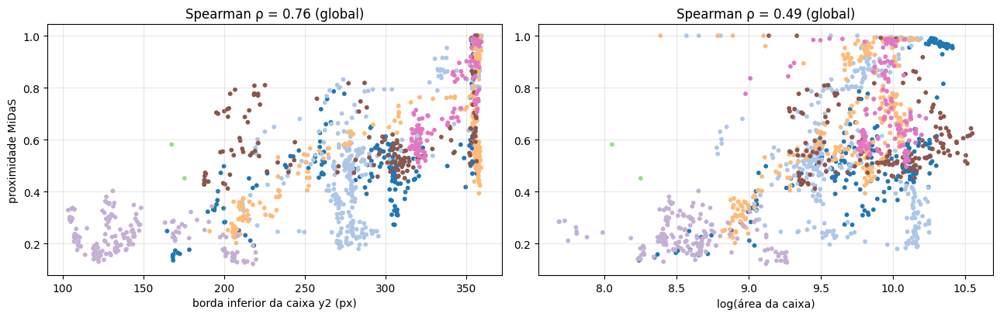

ρ (proximidade × y2), global:            +0.76  (p=2.7e-240)  ← mistura objetos e instantes diferentes
ρ (proximidade × log área), global:      +0.49  (p=3.7e-76)
Concordância par a par no mesmo frame:   94% de 1579 pares
Variação média frame a frame por objeto: 0.026  (amplitude total = 0.88)

Nota: a pista y2 vale para objetos apoiados no chão; o ρ global é indicativo, não prova (amostras correlacionadas no tempo).
A métrica mais confiável é a concordância par a par e, principalmente, a acurácia contra o gabarito manual (6.6b).


In [ ]:
#@title 📐 Validação da profundidade: pistas geométricas e estabilidade temporal
df["area"] = (df["x2"] - df["x1"]) * (df["y2"] - df["y1"])
r_y, p_y = spearmanr(df["closeness"], df["y2"])
r_a, p_a = spearmanr(df["closeness"], np.log(df["area"] + 1))

# Concordância par a par DENTRO do mesmo frame: para dois objetos vistos juntos, o que tem a base mais
# baixa na imagem (y2 maior) deve ter proximidade maior. Pares com diferença desprezível são ignorados.
conc_ok, conc_n = 0, 0
for _, g in df.groupby("frame"):
    v = g[["closeness", "y2"]].to_numpy()
    for i in range(len(v)):
        for j in range(i + 1, len(v)):
            dc, dy = v[i, 0] - v[j, 0], v[i, 1] - v[j, 1]
            if abs(dc) < 0.05 or abs(dy) < 5:
                continue
            conc_n += 1
            conc_ok += int(dc * dy > 0)
conc = conc_ok / conc_n if conc_n else float("nan")

df = df.sort_values(["id", "frame"])
dif = df.groupby("id")["closeness"].diff().abs().dropna()
estab = float(dif.mean()) if len(dif) else float("nan")
amp = df["closeness"].max() - df["closeness"].min()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].scatter(df["y2"], df["closeness"], c=df["id"], cmap="tab20", s=10)
axs[0].set_xlabel("borda inferior da caixa y2 (px)"); axs[0].set_ylabel("proximidade MiDaS")
axs[0].set_title(f"Spearman ρ = {r_y:.2f} (global)")
axs[1].scatter(np.log(df["area"] + 1), df["closeness"], c=df["id"], cmap="tab20", s=10)
axs[1].set_xlabel("log(área da caixa)"); axs[1].set_title(f"Spearman ρ = {r_a:.2f} (global)")
for a in axs:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"ρ (proximidade × y2), global:            {r_y:+.2f}  (p={p_y:.1e})  ← mistura objetos e instantes diferentes")
print(f"ρ (proximidade × log área), global:      {r_a:+.2f}  (p={p_a:.1e})")
print(f"Concordância par a par no mesmo frame:   "
      + (f"{100 * conc:.0f}% de {conc_n} pares" if conc_n else "sem pares (nenhum frame com 2+ objetos distinguíveis)"))
print(f"Variação média frame a frame por objeto: {estab:.3f}  (amplitude total = {amp:.2f})")
print("\nNota: a pista y2 vale para objetos apoiados no chão; o ρ global é indicativo, não prova (amostras correlacionadas no tempo).\n"
      "A métrica mais confiável é a concordância par a par e, principalmente, a acurácia contra o gabarito manual (6.6b).")

### 6.6b Acurácia da escolha do objeto mais próximo (gabarito manual)
O sistema decide qual objeto está mais perto; aqui comparamos essa decisão com a de uma pessoa. A célula abaixo mostra quadros com 2+ objetos (só caixas e IDs). Rotule a olho e preencha o campo na célula seguinte.

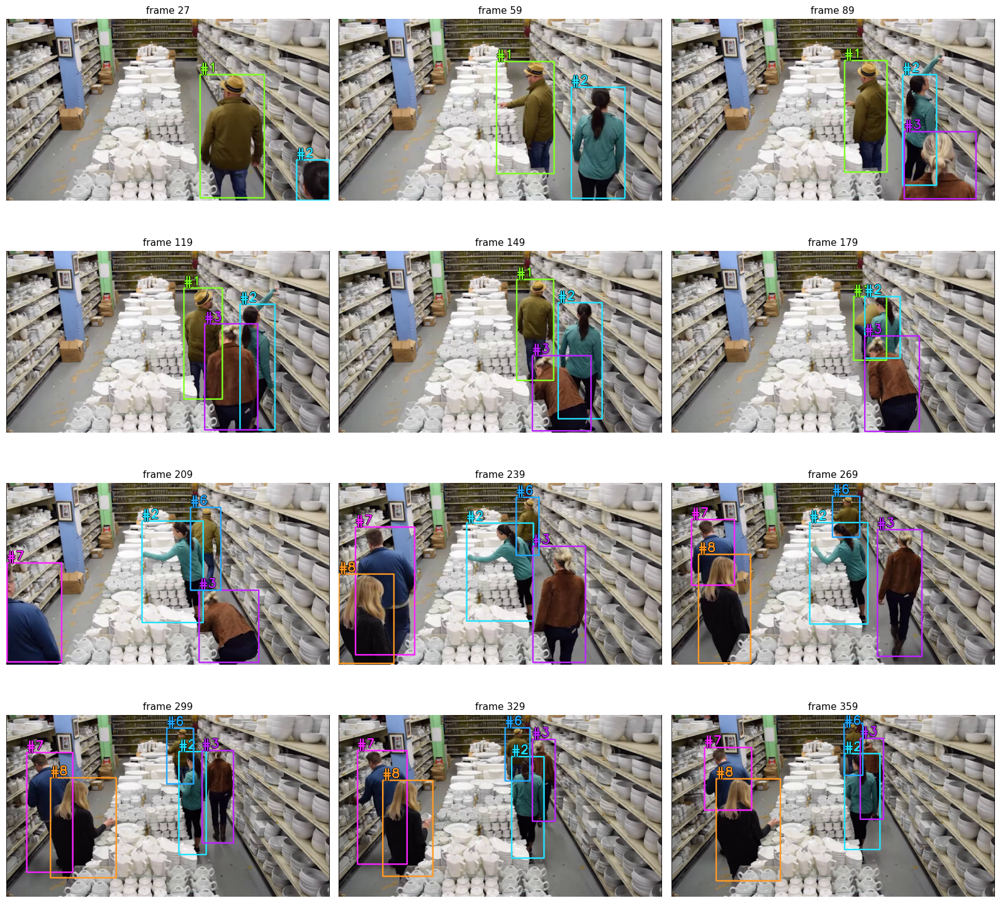

Frames candidatos: [27, 59, 89, 119, 149, 179, 209, 239, 269, 299, 329, 359]
👉 Olhe cada quadro, decida a olho qual objeto está MAIS PERTO da câmera e preencha o campo da próxima célula, no formato  frame:id, frame:id  (ex.: 45:2, 120:3).


In [ ]:
#@title 🖼️ Quadros candidatos para o gabarito manual (só caixas e IDs, sem valores de profundidade)
import math
N_CAND = 12
cand = sorted(int(k) for k in n_por_frame[n_por_frame >= 2].index)
FRAMES_GT = []
if not cand:
    print("Nenhum frame com 2+ objetos: não há o que rotular. Use um vídeo com mais objetos simultâneos.")
else:
    sel = [cand[int(i)] for i in np.linspace(0, len(cand) - 1, min(N_CAND, len(cand)))]
    FRAMES_GT = sorted(set(sel))
    quadros = {}
    for i, fr in enumerate(iter_frames(FONTE, CAMINHO, N_FRAMES, LARGURA)):
        if i in FRAMES_GT:
            quadros[i] = fr
        if i >= FRAMES_GT[-1]:
            break
    cols = 3
    rows = math.ceil(len(FRAMES_GT) / cols)
    fig, axs = plt.subplots(rows, cols, figsize=(16, 3.8 * rows))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs:
        ax.axis("off")
    for ax, k in zip(axs, FRAMES_GT):
        img = quadros[k].copy()
        for _, r in df[df["frame"] == k].iterrows():
            x1, y1, x2, y2 = (int(r["x1"]), int(r["y1"]), int(r["x2"]), int(r["y2"]))
            cor = cor_id(int(r["id"]))
            cv2.rectangle(img, (x1, y1), (x2, y2), cor, 2)
            cv2.putText(img, f"#{int(r['id'])}", (x1, max(18, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4)
            cv2.putText(img, f"#{int(r['id'])}", (x1, max(18, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, cor, 2)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f"frame {k}", fontsize=11)
    plt.tight_layout(); plt.show()
    print("Frames candidatos:", FRAMES_GT)
    print("👉 Olhe cada quadro, decida a olho qual objeto está MAIS PERTO da câmera e preencha o campo da próxima célula, "
          "no formato  frame:id, frame:id  (ex.: 45:2, 120:3).")

In [ ]:
#@title ✍️ Gabarito manual: qual ID está mais perto em cada quadro?
GT_TEXTO = ""  #@param {type:"string"}
# Formato: "frame:id, frame:id". Exemplo: "45:2, 120:3, 200:3". Rotule a olho, sem olhar os números do sistema.

acc_prof = acc_alvo = None
n_gt = 0
gt = {}
for par in [p for p in GT_TEXTO.split(",") if p.strip()]:
    try:
        k, i = par.split(":")
        gt[int(k)] = int(i)
    except ValueError:
        print(f"Entrada ignorada (formato inválido): '{par.strip()}'")

if not gt:
    print("Gabarito vazio: preencha GT_TEXTO (veja os quadros da célula anterior) e rode esta célula de novo. "
          "Sem ele, o relatório informa que a escolha do alvo NÃO foi validada contra a referência humana.")
else:
    linhas = []
    for k, id_gt in sorted(gt.items()):
        g = df[df["frame"] == k]
        if id_gt not in set(g["id"]):
            print(f"Frame {k}: ID {id_gt} não está visível nesse frame; ignorado.")
            continue
        id_prof = int(g.loc[g["closeness"].idxmax(), "id"])           # argmax da profundidade (sem histerese)
        ga = g[g["alvo"]]
        id_alvo = int(ga["id"].iloc[0]) if len(ga) else None            # alvo final do AlvoManager
        linhas.append(dict(frame=k, gabarito=id_gt, profundidade_argmax=id_prof, alvo_sistema=id_alvo,
                           acerto_prof=id_prof == id_gt, acerto_alvo=id_alvo == id_gt))
    if linhas:
        tgt = pd.DataFrame(linhas)
        display(tgt)
        n_gt = len(tgt)
        acc_prof = float(tgt["acerto_prof"].mean())
        acc_alvo = float(tgt["acerto_alvo"].mean())
        print(f"Acurácia do 'mais próximo' pela profundidade (argmax): {100 * acc_prof:.0f}%  ({int(tgt['acerto_prof'].sum())}/{n_gt})")
        print(f"Acurácia do alvo final (com histerese/paciência):      {100 * acc_alvo:.0f}%  ({int(tgt['acerto_alvo'].sum())}/{n_gt})")
        if n_gt < 10:
            print(f"⚠️ Apenas {n_gt} quadros rotulados: o ideal é ≥ 10 para a acurácia ser informativa.")

Gabarito vazio: preencha GT_TEXTO (veja os quadros da célula anterior) e rode esta célula de novo. Sem ele, o relatório informa que a escolha do alvo NÃO foi validada contra a referência humana.


### 6.7 Desempenho computacional

In [ ]:
#@title ⏱️ Tempo por etapa
tab = pd.DataFrame({e: [1000 * np.mean(v), 1000 * np.std(v)] for e, v in tempos.items()},
                   index=["média (ms)", "desvio (ms)"]).T.round(1)
display(tab)
print(f"Taxa média do sistema completo: {1 / np.mean(tempos['total']):.1f} FPS em {device.upper()}")

,média (ms),desvio (ms)
segmentacao,316.3,154.1
profundidade,19.4,9.3
tracking,14.5,5.7
total,350.2,163.8


Taxa média do sistema completo: 2.9 FPS em CUDA


## 7. Conclusões

In [ ]:
#@title 📝 Resumo automático dos resultados
alvo_frames = int(df["alvo"].sum())
ids_alvo = sorted(int(i) for i in df[df["alvo"]]["id"].unique())

# Consistência do alvo: nos frames com 2+ objetos, o alvo é o de maior proximidade?
# (não precisa ser 100%: a histerese segura o alvo atual de propósito)
cons_ok, cons_n = 0, 0
for _, g in df.groupby("frame"):
    if g["id"].nunique() >= 2 and g["alvo"].any():
        cons_n += 1
        cons_ok += int(g.loc[g["closeness"].idxmax(), "alvo"])
consist_alvo = cons_ok / cons_n if cons_n else float("nan")

print("RESUMO")
print("-" * 64)
print(f"Frames processados:                     {N_FRAMES}  (com 2+ objetos: {n_multi})")
print(f"Objetos rastreados (IDs únicos):        {df['id'].nunique()}  (classes: {', '.join(sorted(df['cls'].unique()))})")
print(f"IDs que foram 'alvo' em algum momento:  {ids_alvo}")
print(f"Re-identificações naturais (execução):  {tracker.n_reid}  | retornos naturais ≥{LACUNA_MIN} frames: {len(ev)}")
print(f"IDs únicos com re-ID × sem re-ID:       {abl.loc[0, 'ids_unicos']} × {abl.loc[1, 'ids_unicos']}")
if saida_forcada:
    t = saida_forcada["tabela"]
    print(f"Saída forçada ({saida_forcada['gap']} frames), continuidade do ID: "
          f"com re-ID {t.loc[0, 'continuidade_pct']}% × sem re-ID {t.loc[1, 'continuidade_pct']}%")
else:
    print("Saída forçada:                          não executada (track contínuo curto demais)")
print(f"Profundidade × y2: ρ global = {r_y:+.2f} | concordância par a par = "
      + (f"{100 * conc:.0f}% ({conc_n} pares)" if conc_n else "n/d"))
print(f"Alvo coincide com o mais próximo em:    "
      + (f"{100 * consist_alvo:.0f}% dos {cons_n} frames com 2+ objetos" if cons_n else "n/d"))
print(f"Acurácia vs gabarito manual:            "
      + (f"profundidade {100 * acc_prof:.0f}% | alvo {100 * acc_alvo:.0f}% ({n_gt} quadros)" if n_gt else "não rotulado"))
print(f"Velocidade: {1 / np.mean(tempos['total']):.1f} FPS ({device.upper()})")

RESUMO
----------------------------------------------------------------
Frames processados:                     360  (com 2+ objetos: 331)
Objetos rastreados (IDs únicos):        8  (classes: person)
IDs que foram 'alvo' em algum momento:  [1, 2, 3, 7, 8]
Re-identificações naturais (execução):  1  | retornos naturais ≥5 frames: 1
IDs únicos com re-ID × sem re-ID:       8 × 8
Saída forçada (30 frames), continuidade do ID: com re-ID 100.0% × sem re-ID 0.0%
Profundidade × y2: ρ global = +0.76 | concordância par a par = 94% (1579 pares)
Alvo coincide com o mais próximo em:    94% dos 331 frames com 2+ objetos
Acurácia vs gabarito manual:            não rotulado
Velocidade: 2.9 FPS (CUDA)


### 7.1 Relatório técnico
A célula abaixo monta o relatório técnico do projeto com os números **desta execução**, e só faz afirmações que os resultados sustentam. Ela também salva `relatorio_tecnico.md`.

In [ ]:
#@title 📄 Relatório técnico (gerado a partir dos resultados desta execução)
BAIXAR_RELATORIO = True  #@param {type:"boolean"}
from IPython.display import Markdown


def _n(x, fmt=".2f", suf=""):
    # formata número; devolve 'n/d' para None/NaN
    return "n/d" if x is None or (isinstance(x, float) and np.isnan(x)) else format(x, fmt) + suf


ms = {k: 1000 * float(np.mean(v)) for k, v in tempos.items()}
fps_med = 1 / float(np.mean(tempos["total"]))
h_px = int(round(df["y2"].max())) if len(df) else 0
origem = VIDEO_EXEMPLO if FONTE == "exemplo" else CAMINHO

# --- tabelas em markdown
def _linha(*c): return "| " + " | ".join(str(x) for x in c) + " |"

tab_ids = "\n".join(
    _linha(f"#{i}", g["cls"].iloc[0], int(g["frame"].min()), int(g["frame"].max()), g["frame"].nunique(), f"{g['closeness'].mean():.2f}")
    for i, g in df.groupby("id"))

if saida_forcada:
    t = saida_forcada["tabela"]
    tab_forc = "\n".join(
        _linha(r["config"], r["id_antes"], r["ids_apos"], _n(r["continuidade_pct"], ".0f", "%"), r["ids_unicos"], r["reidentificacoes"])
        for _, r in t.iterrows())
    sec_forc = (f"O alvo (ID #{saida_forcada['oid']}) foi removido artificialmente nos frames "
                f"{saida_forcada['a']}–{saida_forcada['b'] - 1} ({saida_forcada['gap']} frames, acima de `MAX_AGE`={MAX_AGE}), "
                "simulando uma saída do quadro.\n\n"
                "| Configuração | ID antes | IDs depois | Continuidade do ID | IDs únicos | Re-IDs |\n|---|---|---|---|---|---|\n" + tab_forc)
else:
    sec_forc = "Teste não executado: nenhum track contínuo longo o bastante neste vídeo."

# --- discussão condicional (só afirma o que os números sustentam)
disc = []
if n_multi < LIMIAR_MULTI:
    disc.append(f"**Cobertura insuficiente.** Apenas {n_multi} frames têm 2+ objetos; a escolha do objeto mais próximo "
                "foi pouco exercitada e as métricas de profundidade devem ser lidas com cautela.")
else:
    disc.append(f"**Cobertura adequada.** {n_multi} frames com 2+ objetos permitem comparar profundidades.")
if conc_n:
    disc.append(f"**Profundidade.** Em {conc_n} pares de objetos no mesmo frame, {100 * conc:.0f}% respeitaram a pista geométrica "
                f"(base mais baixa = mais perto). " + ("Isso é coerente com a ordenação do MiDaS." if conc >= 0.7
                else "Valor baixo: a pista geométrica pode não valer nesta cena (câmera alta, objetos fora do chão) ou o MiDaS errou a ordem."))
else:
    disc.append("**Profundidade.** Não houve pares de objetos distinguíveis no mesmo frame; a validação geométrica não pôde ser feita.")
if n_gt:
    disc.append(f"**Alvo vs. referência humana.** Em {n_gt} quadros rotulados à mão, o argmax da profundidade acertou "
                f"{100 * acc_prof:.0f}% e o alvo final {100 * acc_alvo:.0f}%."
                + (" Amostra pequena: tratar como indicativo." if n_gt < 10 else ""))
else:
    disc.append("**Alvo vs. referência humana.** Gabarito manual não preenchido: a escolha do alvo **não foi validada** contra uma referência humana.")
if saida_forcada:
    cc, cs = t.loc[0, "continuidade_pct"], t.loc[1, "continuidade_pct"]
    if cc == cc and cc >= 90 and (cs != cs or cs < 50):
        disc.append(f"**Re-identificação.** No teste de saída forçada, a re-ID preservou o ID em {cc:.0f}% dos frames após a volta, "
                    f"contra {_n(cs, '.0f')}% sem ela: o mecanismo funciona quando a aparência (cor) é distintiva.")
    else:
        disc.append(f"**Re-identificação.** No teste de saída forçada a continuidade foi {_n(cc, '.0f')}% com re-ID e {_n(cs, '.0f')}% sem; "
                    "o ganho não ficou demonstrado nesta cena (candidatos: aparência parecida entre objetos, `REID_THR` inadequado).")
if len(ev):
    disc.append(f"**Retornos naturais.** {len(ev)} evento(s) de saída e volta com o mesmo ID foram observados no vídeo.")
else:
    disc.append("**Retornos naturais.** Nenhum objeto saiu e voltou naturalmente neste vídeo; a evidência de re-ID vem apenas do teste forçado.")
if cons_n:
    disc.append(f"**Estabilidade do alvo.** O alvo coincidiu com o objeto de maior proximidade em {100 * consist_alvo:.0f}% dos frames com 2+ objetos"
                + ("." if consist_alvo >= 0.999 else "; a diferença para 100% vem da histerese, que segura o alvo atual até outro ficar `MARGEM_TROCA` mais perto."))

md = f"""# Relatório Técnico — Rastreio e Estimativa de Profundidade em Vídeo

**Equipe:** Augusto Oliveira Codo de Sousa (RM562080), Felipe de Oliveira Cabral (RM561720), Gabriel Tonelli Avelino dos Santos (RM564705), Marcelo Roberto Maso Junior (RM562163), Vinícius Adrian Siqueira de Oliveira (RM564962), Sofia Bueris Netto de Souza (RM565818)

## 1. Objetivo
Dado um vídeo (ou imagens de webcam), localizar e segmentar os objetos, estimar qual deles está mais próximo da câmera e rastreá-lo ao longo do tempo, mantendo sua identidade quando sai e volta ao quadro.

## 2. Método
| Etapa | Técnica | Papel |
|---|---|---|
| Segmentação | Mask R-CNN (ResNet-50 FPN v2, pesos COCO) | máscara, caixa e classe por instância |
| Profundidade | MiDaS small (CNN) | mapa de proximidade relativa; mediana dentro da máscara de cada objeto |
| Associação | Algoritmo húngaro, custo 0,6·(1−IoU) + 0,4·distância de cor HSV | liga detecções a tracks |
| Movimento | Filtro de Kalman de velocidade constante (cx, cy, w, h) | predição durante oclusões curtas |
| Saída/entrada do quadro | Galeria de tracks perdidos + re-identificação por histograma HSV | reativa o ID antigo ao voltar |
| Alvo | Objeto de maior proximidade, com histerese (`MARGEM_TROCA`={MARGEM_TROCA}) e paciência (`PACIENCIA`={PACIENCIA}) | evita alternância e preserva o alvo ausente |

O "RNN" do enunciado foi interpretado como R-CNN (rede convolucional por regiões), a família de modelos de segmentação de instâncias.

## 3. Configuração do experimento
| Item | Valor |
|---|---|
| Fonte | {origem} |
| Frames processados / FPS do vídeo | {N_FRAMES} / {FPS_VIDEO:.1f} |
| Largura de processamento | {LARGURA} px |
| Dispositivo | {device.upper()} |
| `SCORE_MIN`, `MAX_AGE`, `MIN_HITS`, `GATE` | {SCORE_MIN}, {MAX_AGE}, {MIN_HITS}, {GATE} |
| `MAX_LOST`, `REID_THR` | {MAX_LOST}, {REID_THR} |
| Classes de interesse | {CLASSES_INTERESSE or 'todas'} |

## 4. Resultados
### 4.1 Cobertura e identidades
{N_FRAMES} frames processados; {cobertura['frames_com_objeto']} com ao menos um objeto e **{n_multi} com dois ou mais** (máximo simultâneo: {cobertura['max_simultaneos']}).

| ID | Classe | Primeiro frame | Último frame | Frames visíveis | Proximidade média |
|---|---|---|---|---|---|
{tab_ids}

Re-identificações na execução principal: {tracker.n_reid}. Ablação natural (com × sem re-ID): {abl.loc[0, 'ids_unicos']} × {abl.loc[1, 'ids_unicos']} IDs únicos.

### 4.2 Teste de saída forçada
{sec_forc}

### 4.3 Profundidade
- Spearman proximidade × y2 (global): {_n(r_y, '+.2f')}; × log(área): {_n(r_a, '+.2f')}. Valores globais misturam objetos e instantes diferentes; servem só como indício.
- Concordância par a par no mesmo frame: {(f'{100 * conc:.0f}% de {conc_n} pares') if conc_n else 'n/d (sem pares)'}.
- Variação média frame a frame da proximidade de um mesmo objeto: {_n(estab, '.3f')} (amplitude total {_n(amp, '.2f')}).

### 4.4 Seleção do alvo
- IDs que foram alvo: {ids_alvo}.
- Coincidência alvo × objeto mais próximo em frames com 2+ objetos: {(f'{100 * consist_alvo:.0f}% de {cons_n} frames') if cons_n else 'n/d'}.
- Acurácia contra gabarito manual: {(f'argmax da profundidade {100 * acc_prof:.0f}% | alvo final {100 * acc_alvo:.0f}% ({n_gt} quadros)') if n_gt else 'não rotulado'}.

### 4.5 Desempenho
| Etapa | Tempo médio (ms) |
|---|---|
| Segmentação (Mask R-CNN) | {ms['segmentacao']:.1f} |
| Profundidade (MiDaS small) | {ms['profundidade']:.1f} |
| Tracking + seleção de alvo | {ms['tracking']:.1f} |
| **Total por frame** | **{ms['total']:.1f}** (≈ {fps_med:.1f} FPS em {device.upper()}) |

## 5. Discussão
""" + "\n".join(f"- {p}" for p in disc) + f"""

## 6. Limitações
- A profundidade é relativa e normalizada por frame (percentis 2–98); não é distância em metros.
- A re-identificação usa apenas cor (HSV): objetos da mesma classe com cores parecidas podem ser confundidos.
- O teste de saída forçada remove detecções da cache; demonstra o mecanismo, mas não substitui um retorno natural.
- O gabarito manual depende do julgamento visual de quem rotula e, por padrão, usa poucos quadros.
- Parâmetros (`SCORE_MIN`, `MAX_AGE`, `REID_THR`, `MARGEM_TROCA`) dependem da cena.

## 7. Trabalhos futuros
Profundidade métrica (ZoeDepth, Depth Anything), embeddings de ReID aprendidos, associação em duas etapas (ByteTrack) e acompanhamento de múltiplos alvos.

## 8. Reprodutibilidade
Notebook único para o Google Colab (GPU T4). Execute com *Ambiente de execução → Executar tudo*; os parâmetros ficam no formulário da seção 2 e o vídeo, os gráficos e este relatório são gerados na própria execução.
"""

with open("relatorio_tecnico.md", "w", encoding="utf-8") as f:
    f.write(md)
display(Markdown(md))
if BAIXAR_RELATORIO:
    try:
        from google.colab import files
        files.download("relatorio_tecnico.md")
    except Exception:
        pass

# Relatório Técnico — Rastreio e Estimativa de Profundidade em Vídeo

**Equipe:** Augusto Oliveira Codo de Sousa (RM562080), Felipe de Oliveira Cabral (RM561720), Gabriel Tonelli Avelino dos Santos (RM564705), Marcelo Roberto Maso Junior (RM562163), Vinícius Adrian Siqueira de Oliveira (RM564962), Sofia Bueris Netto de Souza (RM565818)

## 1. Objetivo
Dado um vídeo (ou imagens de webcam), localizar e segmentar os objetos, estimar qual deles está mais próximo da câmera e rastreá-lo ao longo do tempo, mantendo sua identidade quando sai e volta ao quadro.

## 2. Método
| Etapa | Técnica | Papel |
|---|---|---|
| Segmentação | Mask R-CNN (ResNet-50 FPN v2, pesos COCO) | máscara, caixa e classe por instância |
| Profundidade | MiDaS small (CNN) | mapa de proximidade relativa; mediana dentro da máscara de cada objeto |
| Associação | Algoritmo húngaro, custo 0,6·(1−IoU) + 0,4·distância de cor HSV | liga detecções a tracks |
| Movimento | Filtro de Kalman de velocidade constante (cx, cy, w, h) | predição durante oclusões curtas |
| Saída/entrada do quadro | Galeria de tracks perdidos + re-identificação por histograma HSV | reativa o ID antigo ao voltar |
| Alvo | Objeto de maior proximidade, com histerese (`MARGEM_TROCA`=0.15) e paciência (`PACIENCIA`=60) | evita alternância e preserva o alvo ausente |

O "RNN" do enunciado foi interpretado como R-CNN (rede convolucional por regiões), a família de modelos de segmentação de instâncias.

## 3. Configuração do experimento
| Item | Valor |
|---|---|
| Fonte | store-aisle-detection.mp4 |
| Frames processados / FPS do vídeo | 360 / 12.0 |
| Largura de processamento | 640 px |
| Dispositivo | CUDA |
| `SCORE_MIN`, `MAX_AGE`, `MIN_HITS`, `GATE` | 0.5, 15, 3, 0.75 |
| `MAX_LOST`, `REID_THR` | 120, 0.45 |
| Classes de interesse | person, car, bicycle, motorcycle, bus, truck, dog, cat |

## 4. Resultados
### 4.1 Cobertura e identidades
360 frames processados; 360 com ao menos um objeto e **331 com dois ou mais** (máximo simultâneo: 6).

| ID | Classe | Primeiro frame | Último frame | Frames visíveis | Proximidade média |
|---|---|---|---|---|---|
| #1 | person | 0 | 192 | 191 | 0.54 |
| #2 | person | 27 | 359 | 331 | 0.58 |
| #3 | person | 82 | 359 | 278 | 0.66 |
| #4 | person | 103 | 104 | 2 | 0.52 |
| #6 | person | 192 | 359 | 168 | 0.23 |
| #7 | person | 206 | 359 | 154 | 0.60 |
| #8 | person | 227 | 359 | 133 | 0.73 |
| #12 | person | 323 | 347 | 2 | 0.59 |

Re-identificações na execução principal: 1. Ablação natural (com × sem re-ID): 8 × 8 IDs únicos.

### 4.2 Teste de saída forçada
O alvo (ID #2) foi removido artificialmente nos frames 181–210 (30 frames, acima de `MAX_AGE`=15), simulando uma saída do quadro.

| Configuração | ID antes | IDs depois | Continuidade do ID | IDs únicos | Re-IDs |
|---|---|---|---|---|---|
| com re-identificação | 2 | [2] | 100% | 8 | 2 |
| sem re-identificação | 2 | [8] | 0% | 9 | 0 |

### 4.3 Profundidade
- Spearman proximidade × y2 (global): +0.76; × log(área): +0.49. Valores globais misturam objetos e instantes diferentes; servem só como indício.
- Concordância par a par no mesmo frame: 94% de 1579 pares.
- Variação média frame a frame da proximidade de um mesmo objeto: 0.026 (amplitude total 0.88).

### 4.4 Seleção do alvo
- IDs que foram alvo: [1, 2, 3, 7, 8].
- Coincidência alvo × objeto mais próximo em frames com 2+ objetos: 94% de 331 frames.
- Acurácia contra gabarito manual: não rotulado.

### 4.5 Desempenho
| Etapa | Tempo médio (ms) |
|---|---|
| Segmentação (Mask R-CNN) | 316.3 |
| Profundidade (MiDaS small) | 19.4 |
| Tracking + seleção de alvo | 14.5 |
| **Total por frame** | **350.2** (≈ 2.9 FPS em CUDA) |

## 5. Discussão
- **Cobertura adequada.** 331 frames com 2+ objetos permitem comparar profundidades.
- **Profundidade.** Em 1579 pares de objetos no mesmo frame, 94% respeitaram a pista geométrica (base mais baixa = mais perto). Isso é coerente com a ordenação do MiDaS.
- **Alvo vs. referência humana.** Gabarito manual não preenchido: a escolha do alvo **não foi validada** contra uma referência humana.
- **Re-identificação.** No teste de saída forçada, a re-ID preservou o ID em 100% dos frames após a volta, contra 0% sem ela: o mecanismo funciona quando a aparência (cor) é distintiva.
- **Retornos naturais.** 1 evento(s) de saída e volta com o mesmo ID foram observados no vídeo.
- **Estabilidade do alvo.** O alvo coincidiu com o objeto de maior proximidade em 94% dos frames com 2+ objetos; a diferença para 100% vem da histerese, que segura o alvo atual até outro ficar `MARGEM_TROCA` mais perto.

## 6. Limitações
- A profundidade é relativa e normalizada por frame (percentis 2–98); não é distância em metros.
- A re-identificação usa apenas cor (HSV): objetos da mesma classe com cores parecidas podem ser confundidos.
- O teste de saída forçada remove detecções da cache; demonstra o mecanismo, mas não substitui um retorno natural.
- O gabarito manual depende do julgamento visual de quem rotula e, por padrão, usa poucos quadros.
- Parâmetros (`SCORE_MIN`, `MAX_AGE`, `REID_THR`, `MARGEM_TROCA`) dependem da cena.

## 7. Trabalhos futuros
Profundidade métrica (ZoeDepth, Depth Anything), embeddings de ReID aprendidos, associação em duas etapas (ByteTrack) e acompanhamento de múltiplos alvos.

## 8. Reprodutibilidade
Notebook único para o Google Colab (GPU T4). Execute com *Ambiente de execução → Executar tudo*; os parâmetros ficam no formulário da seção 2 e o vídeo, os gráficos e este relatório são gerados na própria execução.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.2 Limitações e trabalhos futuros

**Limitações.**

* A profundidade é **relativa** e normalizada por frame, então não é uma distância em metros e pode variar um pouco entre frames.
* A re-identificação usa só cor (HSV): objetos da mesma classe com cores parecidas podem ser confundidos.
* O teste de saída forçada demonstra o mecanismo de re-ID, mas não substitui um retorno natural de objeto.
* O gabarito manual depende do julgamento visual e tem poucos quadros por padrão.
* Parâmetros como `SCORE_MIN`, `MAX_AGE`, `REID_THR` e `MARGEM_TROCA` dependem da cena e podem ser ajustados pelo formulário da seção 2.

**Trabalhos futuros:** profundidade métrica (ZoeDepth / Depth Anything), embeddings de ReID, associação em duas etapas (ByteTrack) e acompanhamento de múltiplos alvos.


## 8. Referências

* He et al., *Mask R-CNN*, ICCV 2017.
* Ranftl et al., *Towards Robust Monocular Depth Estimation: Mixing Datasets for Zero-shot Cross-dataset Transfer* (MiDaS), TPAMI 2022.
* Bewley et al., *Simple Online and Realtime Tracking* (SORT), ICIP 2016.
* Kuhn, *The Hungarian Method for the Assignment Problem*, 1955.
* Documentação: PyTorch / torchvision, OpenCV, SciPy.